In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer

In [3]:
# Load dataset
data = load_breast_cancer(as_frame=True)
df = data.frame
df.to_csv("breast_cancer.csv")
df = pd.read_csv("breast_cancer.csv")
print(df.head(3))

   Unnamed: 0  mean radius  mean texture  mean perimeter  mean area  \
0           0        17.99         10.38           122.8     1001.0   
1           1        20.57         17.77           132.9     1326.0   
2           2        19.69         21.25           130.0     1203.0   

   mean smoothness  mean compactness  mean concavity  mean concave points  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   

   mean symmetry  ...  worst texture  worst perimeter  worst area  \
0         0.2419  ...          17.33            184.6      2019.0   
1         0.1812  ...          23.41            158.8      1956.0   
2         0.2069  ...          25.53            152.5      1709.0   

   worst smoothness  worst compactness  worst concavity  worst concave points  \
0            0.1622             0.6656          

In [5]:
# Prepare features and target
x = df.drop('target', axis=1)
y = df.target

In [6]:
# Standardize the data
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [7]:
# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42)

In [8]:
# Model 1: Original Data[cite: 32]
knn_clf = RandomForestClassifier(random_state=42)
knn_clf.fit(x_train, y_train)
y_pred = knn_clf.predict(x_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy is", acc)

Accuracy is 0.9649122807017544


In [10]:
# Model 2: PCA[cite: 32]
pca_model = PCA(n_components=2, random_state=42)
x_train_pca = pca_model.fit_transform(x_train)
x_test_pca = pca_model.transform(x_test)

pca_clf = RandomForestClassifier(random_state=42)
pca_clf.fit(x_train_pca, y_train)
y_pred_pca = pca_clf.predict(x_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)
print("Accuracy is", acc_pca)

Accuracy is 0.9824561403508771


In [12]:
# Model 3: t-SNE[cite: 32]
tsne_model = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
x_tsne_full = tsne_model.fit_transform(x_scaled)

x_train_tsne, x_test_tsne, y_train_tsne, y_test_tsne = train_test_split(x_tsne_full, y, test_size=0.2, random_state=42)

tsne_clf = RandomForestClassifier(random_state=42)
tsne_clf.fit(x_train_tsne, y_train_tsne)
y_pred_tsne = tsne_clf.predict(x_test_tsne)
acc_tsne = accuracy_score(y_test_tsne, y_pred_tsne)
print("Accuracy is", acc_tsne)

Accuracy is 0.9473684210526315


In [13]:
# Print Summary[cite: 32]
print(f"Original Data Accuracy: {acc}")
print(f"PCA Accuracy: {acc_pca}")
print(f"tsne Accuracy: {acc_tsne}")

Original Data Accuracy: 0.9649122807017544
PCA Accuracy: 0.9824561403508771
tsne Accuracy: 0.9473684210526315


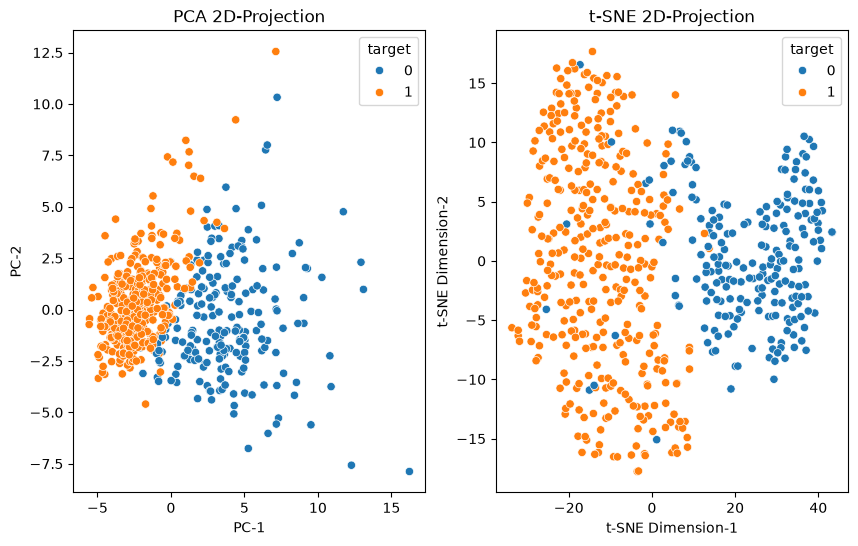

In [14]:
# Visualization[cite: 32, 33]
x_pca_full = pca_model.fit_transform(x_scaled)

plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
sns.scatterplot(x=x_pca_full[:, 0], y=x_pca_full[:, 1], hue=y)
plt.xlabel("PC-1")
plt.ylabel("PC-2")
plt.title("PCA 2D-Projection")

plt.subplot(1,2,2)
sns.scatterplot(x=x_tsne_full[:, 0], y=x_tsne_full[:, 1], hue=y)
plt.xlabel("t-SNE Dimension-1")
plt.ylabel("t-SNE Dimension-2")
plt.title("t-SNE 2D-Projection")
plt.show()